In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/dylanmalis-collab/titanic_csv/main/dataset-titanic-6afac2fa9ddd8043393546.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# nettoyage 1 dylan
df1 = df.copy()
df1.shape

(891, 12)

In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Sélection des features pertinentes

# Je garde en feature --> ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

# Je jette --> ["PassengerId, Name, Ticket, Cabin"]
# -PassengerId n'a aucun intérêt prédictif direct.
# -Name peu exploitable sans feature engineering "lourd", malgré quelques titres intéressant (Mr, Miss, Master, etc...),
# -Ticket est porteur de trop de variabilité (cardinalité élevé) et donc de bruit en cas d'encodage disjonctif,
# -Cabin contient énormément de manquant (687/891) et ne serait au mieux qu'un proxi de Pclass (Bruit + trop lacunaire).

# La cible --> ["Survived"]

In [ ]:
df1.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Gestion des valeurs aberantes :
# Ici le calcule de IQR et des Outliers serait trompeur, car les valeur dite "aberrantes", ne sont pas forcément des erreurs et reste largement plausible dans la réalitée (age 80 et ticket à 512.329200 ou à 0)
# Ne pas ce laisser décontenancer par les décimals des prix, qui sont cohérent avec le fonctionnement de la Livre Sterling de 1912.
# Ticket gratuit pour le personnel et Ticket premium à tarif majoré sony valide historiquement.

In [ ]:
# Gestion des manquants: Age et Embarked, on toutes les 2 des valeurs manquante.

# Age est une variable numérique avec environ 20 % de valeurs manquantes. Il est intéressant de les remplacer par la MEDIANE, moins sensible aux valeurs extrêmes que la MOYENNE.
df1["Age"] = df1["Age"].fillna(df1["Age"].median())

# Embarked ne présente que 2 valeurs manquantes. Il est préférable de supprimer ces lignes (perte négligeable de données) plutôt que d'imputer le MODE ou de créer une catégorie "Unknown".
df1 = df1.dropna(subset=["Embarked"])

In [ ]:
# Feature Engineering

# Création de la colonne FamilySize -> nombre de membres de la famille à bord (+ le passager lui même)
df1["FamilySize"] = df1["SibSp"] + df1["Parch"] + 1

# Création de la colonne IsChild -> indique si le passager est un enfant de moins de 16 ans (1 = oui, 0 = non)
df1["IsChild"] = (df1["Age"] < 16).astype(int) # enfant ou non

# Création de la colonne Sex_Pclass -> combinaison du sexe et de la classe du passager (profil sociodémographique)
df1["Sex_Pclass"] = df1["Sex"] + "_" + df1["Pclass"].astype(str) # infos socio-sexuel

#Création de la colonne TicketGroupSize -> nombre de passagers partageant le même numéro de billet
df1["TicketGroupSize"] = df1.groupby("Ticket")["Ticket"].transform("size") # groupe avec même ticket

# Création de la colonne Title -> extraction du titre depuis le nom du passager avec regex
df1["Title"] = df1["Name"].str.extract(r",\s*(.*?)\.", expand=False)

In [ ]:
# Dénombrement des occurrences de chaque titre
df1["Title"].value_counts()

,count
Title,
Mr,517
Miss,181
Mrs,124
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [ ]:
# Simplification des catégories.

# Regroupement des titres étranger parfaitement équivalents
df1["Title"] = df1["Title"].replace({"Mme": "Mrs","Mlle": "Miss","Ms": "Miss"})

# Regroupement des titres rares
df1["Title"] = df1["Title"].where(df1["Title"].isin(["Mr", "Mrs", "Miss", "Master"]),"Rare") # Tout titres n'étant pas directement rattaché a un titre courant est placéé dans "Rare"

# Vérification
df1["Title"].value_counts()


,count
Title,
Mr,517
Miss,184
Mrs,125
Master,40
Rare,23


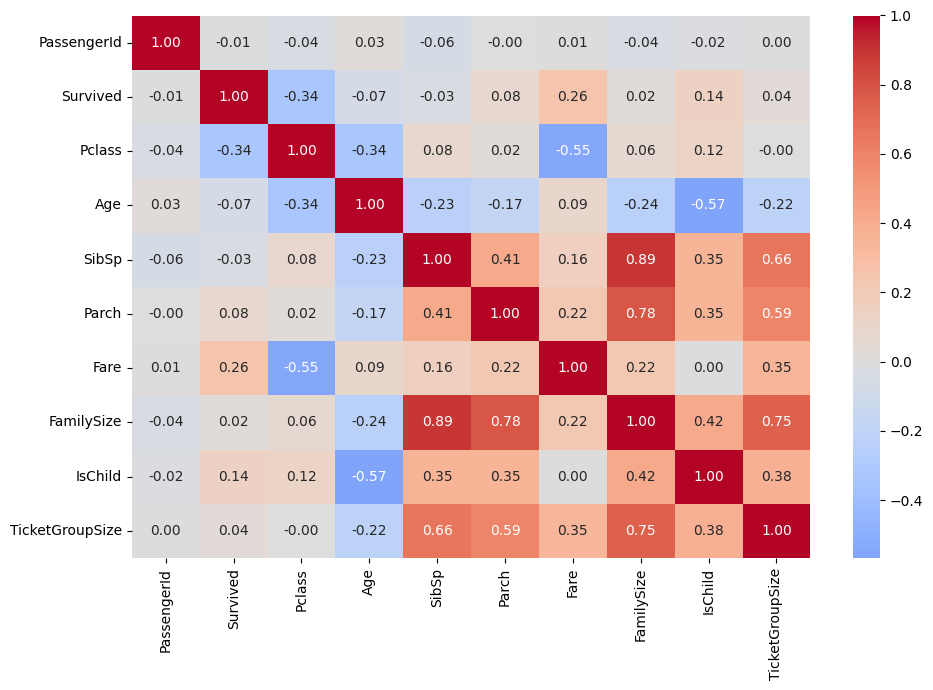

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Matrice de corrélation des variables numériques
plt.figure(figsize=(10, 7))

sns.heatmap(df1.select_dtypes(include="number").corr(),annot=True,fmt=".2f",center=0,cmap="coolwarm")

plt.tight_layout()
plt.show()

In [ ]:
# Sélection des features pertinentes

# Je garde en feature --> ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"] + 3 nouvelles features ["IsChild", "Title", "Sex_Pclass"]

# J'écarte --> ["PassengerId, Name, Ticket, Cabin"] + [ "FamilySize", "TicketGroupSize"]
# -PassengerId n'a aucun intérêt prédictif direct.
# -Name peu exploitable en l'état, nous avons extrait les titres,
# -Ticket est porteur de trop de variabilité (cardinalité élevé) et donc de bruit en cas d'encodage disjonctif,
# -Cabin contient énormément de manquant (687/891) et ne serait au mieux qu'un proxi de Pclass (Bruit + trop lacunaire).
# -FamilySize Faible corrélation a la survie (notre cible) et forte redondance avec "SibSp" et "Parch".
# -TicketGroupSize idem, fortement corrélée à la famille en générale


# -Title apporte une composante sociologique complémentaire à Pclass, elle agglomère les titres similaire et classe les titre trop peu fréquent dans la catégorie "Rare"
# -Sex_Pclass combine le sexe et la classe sociale, permettant de mieux représenter leur influence conjointe sur la survie.
# -IsChild distingue les enfants des adultes et présente la meilleure corrélation avec Survived (+0,14) parmi les nouvelles variables numériques, tout en étant moins redondante que FamilySize et TicketGroupSize.

# La cible --> ["Survived"]

In [ ]:
X = df1[["Pclass", "Sex", "Age","SibSp", "Parch",  "Fare", "Embarked","Title", "IsChild", "Sex_Pclass"]] #Features nettoyés + 3 nouvelles features "Title", "IsChild", "Sex_Pclass"
y = df1["Survived"] #Target


In [ ]:
# RandomForestClassifier
from sklearn.model_selection import train_test_split

# Division des données avec train_test_split / Vérification de la distribution
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, train_size=0.75, random_state=42, stratify = y)

# 75% des données pour le jeux d'entrainement / 25% pour le test.
# random_state = 42 (reproductibilité)
# stratify = y : Equilibre des classes (Survivant / Décès) dans la cible, Evite d'avoir trop peu de l'un ou de l'autre dans y_test et y_train.

In [ ]:
# Prétraitement des données : encodage des variables catégorielles
# Les arbres de décision sont peu/insensibles au scaling des variables numériques (pas de StandardScaler ici).
# Les variables catégorielles doivent cependant être encodées pour être exploitables par le modèle.

# Bien que Pclass soit une variable catégorielle ordinale, nous avons choisi de ne pas l'encoder et de la traiter comme numérique.
# Nous partons du postulat que les écarts entre les classes 1 et 2, et entre les classes 2 et 3, sont équivalents.

# Imports
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Initialisation du prétraitement : encodage One-Hot des variables catégorielles
preprocessor_rf = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex", "Embarked", "Title","Sex_Pclass"])],
    remainder="passthrough")  # Conservation des autres colonnes sans transformation

In [ ]:
# Import du modèle + pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

modelRFC = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("RandomForest", RandomForestClassifier(random_state=42))]) # Initialisation du modèle avec les hyperparamètres par défaut (random_state = 42 pour la reproductibilité)

# Entraînement du modèle sur les données prétraitées
modelRFC.fit(X_train1, y_train1)




/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Sex', 'Embarked', 'Title',
                                                   'Sex_Pclass'])])),
                ('RandomForest', RandomForestClassifier(random_state=42))])

In [ ]:
# Évaluation de l'accuracy sur le train et le test
# Par défaut, ".score" renvoi à l'accurancy score.

# Nous privilégions l'accuracy car les classes sont modérément déséquilibrées (62 % de décès, 38 % de survivants) et les erreurs sont considérées comme équivalentes.
# D'autres métriques existent (precision, recall, F1-score, ROC-AUC), mais l'accuracy suffit ici pour comparer simplement nos modèles.

print("Accuracy Train :", modelRFC.score(X_train1, y_train1))
print("Accuracy Test  :", modelRFC.score(X_test1, y_test1))

Accuracy Train : 0.984984984984985
Accuracy Test  : 0.8071748878923767


In [ ]:
# Accuracy Train : 98,50 % contre Accuracy Test : 80,72 %.

# Le modèle présente un surapprentissage important (overfitting), avec un écart de 17,78 points de pourcentage entre les deux scores !
# C'est un comportement possible, et même attendu dans notre cas, pour des modèles à base d'arbres, même avec un RandomForest...

# Il faut ajuster les hyperparamètres du modèle pour améliorer sa généralisation sur notre dataset Titanic.
# Le plus simple (mais coûteux en ressources) serait d'utiliser GridSearchCV, qui combine la validation croisée (cross-validation) et la recherche automatisée de la meilleure combinaison d'hyperparamètres.
# Ou RandomizedSearchCV, moins gourmand, mais plus aléatoir dans ses résultats !

In [ ]:
# Sans les 3 nouvelles features "Title", "IsChild", "Sex_Pclass"

X_raw = df1[["Pclass", "Sex", "Age","SibSp", "Parch",  "Fare", "Embarked"]] #features nettoyés sans les nouvelle feature pour comparaison
y_raw = df1["Survived"]

X_train1_raw, X_test1_raw, y_train1_raw, y_test1_raw = train_test_split(X_raw, y_raw, train_size=0.75, random_state=42, stratify = y)

preprocessor_rf_raw = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex", "Embarked"])],
    remainder="passthrough")

modelRFC_raw = Pipeline([
    ("preprocessor_raw", preprocessor_rf_raw),
    ("RandomForest_raw", RandomForestClassifier(random_state=42))])

modelRFC_raw.fit(X_train1_raw, y_train1_raw)
print("Accuracy Train Raw :", modelRFC_raw.score(X_train1_raw, y_train1_raw))
print("Accuracy Test Raw :", modelRFC_raw.score(X_test1_raw, y_test1_raw))

Accuracy Train Raw : 0.9834834834834835
Accuracy Test Raw : 0.7982062780269058


In [ ]:
# Comparaison avec et sans Feature Engineering :
# L'ajout de Title, IsChild et Sex_Pclass améliore légèrement l'accuracy Test (79,82 % -> 80,72 %).
# L'accuracy Train reste quasiment identique (98,35 % -> 98,50 %).
# Il y a donc bien une progression générale quoique légère a l'incorporation des nouvelles variable

# Dans les faits, les nouvelle feature on très légèrement diminuer l'overfitting. Mais c'est l'optimisation des hyperparamètres avec GridSearchCV ou RandomizedSearchCV qui améliorera significativement le résultat.

In [ ]:
# Optimisation des hyperparamètres avec RandomizedSearchCV :
# Pour des raisons de ressources limité (GoogleCollab) nous utiliserons RandomizedSearchCV plutôt que GridSearchCV

# Imports
from sklearn.model_selection import RandomizedSearchCV

# Hyperparamètres à tester
param_rf = {
    "RandomForest__n_estimators": [100, 150, 200], # Nombre d'arbres dans la foret
    "RandomForest__max_depth": [3, 5, 7, 10, None], # Profondeur maximale de chaque arbre
    "RandomForest__min_samples_split": [2, 5, 10], # Nombre minimal d'observations pour pouvoir diviser un nœud
    "RandomForest__min_samples_leaf": [1, 2, 4], # Nombre minimal d'observations dans chaque feuille
    "RandomForest__max_features": ["sqrt", "log2"] # Nombre de features choisi par le modèle selon loi mathématique : racine carré(N_features) ou  Log2(N_feature)
}

# Recherche aléatoire des meilleures combinaisons
random_search_rf = RandomizedSearchCV(estimator=modelRFC, param_distributions=param_rf, n_iter=30, cv=5, scoring="accuracy", n_jobs=-1, random_state=42)

# Entraînement et validation croisée
random_search_rf.fit(X_train1, y_train1)

# Résultats
print("Meilleurs paramètres :", random_search_rf.best_params_)
print("Accuracy CV :", random_search_rf.best_score_)
print("Accuracy Train :", random_search_rf.score(X_train1, y_train1))
print("Accuracy Test :", random_search_rf.score(X_test1, y_test1))


Meilleurs paramètres : {'RandomForest__n_estimators': 200, 'RandomForest__min_samples_split': 5, 'RandomForest__min_samples_leaf': 1, 'RandomForest__max_features': 'log2', 'RandomForest__max_depth': 10}
Accuracy CV : 0.8348557962069354
Accuracy Train : 0.9174174174174174
Accuracy Test : 0.8116591928251121


In [ ]:
# Optimisation des hyperparamètres avec RandomizedSearchCV : Conclusion

# L'accuracy Train diminue de 98,50 % à 91,74 %, tandis que l'accuracy Test progresse légèrement de 80,72 % à 81,17 % (+0,45 point).
# L'écart Train/Test passe de 17,78 à 10,58 points, soit une réduction d'environ 40,5 % du décalage initial !
# Le modèle présente donc un surapprentissage moins marqué, mais toujours présent (> 0.1 ou 10 points de pourcentage).

# L'accuracy moyenne en validation croisée (83,49 %) suggère une capacité de généralisation supérieure à celle observée sur le test final.
# L'optimisation améliore surtout la généralisation et la régularité du modèle,  mais avec un gain prédictif limité.

In [ ]:
# RegressionLogistic
from sklearn.model_selection import train_test_split

# Division des données avec train_test_split / Vérification de la distribution
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, train_size=0.75, random_state=42, stratify = y)

# 75% des données pour le jeux d'entrainement / 25% pour le test.
# random_state = 42 (reproductibilité)
# stratify = y : Equilibre des classes (Survivant / Décès) dans la cible, Evite d'avoir trop peu de l'un ou de l'autre dans y_test et y_train.

In [ ]:
# Prétraitement des données : encodage des variables catégorielles + normalisation des numériques
# Les variables catégorielles doivent cependant être encodées pour être exploitables par le modèle.
# Les variables numérique doivent être Normalisé pour neutraliser leur ordre de grandeur différente.

# Bien que Pclass soit une variable catégorielle ordinale, nous avons choisi de ne pas l'encoder et de la traiter comme numérique.
# Nous partons du postulat que les écarts entre les classes 1 et 2, et entre les classes 2 et 3, sont équivalents.

# Imports
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Initialisation du prétraitement : encodage One-Hot des variables catégorielles et Scaling des variable numérique
preprocessor_rl = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex", "Embarked","Title","Sex_Pclass"]),
        ("num", StandardScaler(), ["Pclass", "Age", "SibSp", "Parch", "Fare","IsChild"])]) # Normalisation des variables numériques



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

modelRL = Pipeline([
    ("preprocessor", preprocessor_rl),
    ("regression", LogisticRegression(max_iter=1000))]) # random_state=42 inutile avec le solveur lbfgs par défaut

modelRL.fit(X_train1, y_train1)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Sex', 'Embarked', 'Title',
                                                   'Sex_Pclass']),
                                                 ('num', StandardScaler(),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare',
                                                   'IsChild'])])),
                ('regression', LogisticRegression(max_iter=1000))])

In [ ]:
from sklearn.metrics import accuracy_score # Equivalent au .score

# initialistion des y prédictif de test et train
y_pred_train = modelRL.predict(X_train1)
y_pred_test = modelRL.predict(X_test1)

# Utilisation de l'Accurancy_score
print("Accuracy Train :", accuracy_score(y_train1, y_pred_train))
print("Accuracy Test :", accuracy_score(y_test1, y_pred_test))




Accuracy Train : 0.8348348348348348
Accuracy Test : 0.8251121076233184


In [ ]:
# La régression logistique obtient une accuracy de 83,48 % sur le Train et de 82,51 % sur le Test.
# Le faible écart (0,97 point de pourcentage) ne suggère pas de surapprentissage (overfitting) important.
# Les performances sont satisfaisantes et indiquent une bonne capacité de généralisation sur le jeu de test.

In [ ]:
# Sans les 3 nouvelles features "Title", "IsChild", "Sex_Pclass"


X_train2_raw, X_test2_raw, y_train2_raw, y_test2_raw = train_test_split(X_raw, y_raw, train_size=0.75, random_state=42, stratify = y)

preprocessor_rl_raw = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex", "Embarked"]),
        ("num", StandardScaler(), ["Pclass", "Age", "SibSp", "Parch", "Fare"])]) # Normalisation des variables numériques

modelRL_raw = Pipeline([
    ("preprocessor_rl_raw", preprocessor_rl_raw),
    ("LogisticRegression_raw", LogisticRegression(max_iter=1000))])

modelRL_raw.fit(X_train2_raw, y_train2_raw)
print("Accuracy Train Raw :", modelRL_raw.score(X_train2_raw, y_train2_raw))
print("Accuracy Test Raw :", modelRL_raw.score(X_test2_raw, y_test2_raw))

Accuracy Train Raw : 0.8003003003003003
Accuracy Test Raw : 0.7802690582959642


In [ ]:
# L'ajout des trois nouvelles features améliore les performances de la régression logistique :
# l'accuracy Train passe de 80,03 % à 83,48 % (+3,45 points) et l'accuracy Test de 78,03 % à 82,51 % (+4,48 points).
# Ces nouvelles variables apportent donc des informations utiles au modèle, sans accentuer le surapprentissage.
# L'écart Train/Test diminue même de 2,00 à 0,97 point de pourcentage, ce qui est encourageant pour la généralisation.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparamètres à tester
param_rl = {
    "regression__C": [0.01, 0.1, 0.5, 1, 2, 5, 10],             # Force inverse de la régularisation (plus C est faible, plus la régularisation est forte)
    "regression__solver": ["lbfgs", "liblinear", "newton-cg"],  # Algorithme d'optimisation utilisé pour calculer les coefficients ("liblinear" et "newton-cg" sensible a random_state)
    "regression__class_weight": [None, "balanced"],             # Pondération des classes -> uniforme ou ajustée selon leur fréquence
    "regression__random_state": [42]}                           # Fixe l'aléatoire de certains solveurs ("liblinear" et "newton-cg") pour garantir la reproductibilité

# Recherche aléatoire des meilleures combinaisons d'hyperparamètres
random_search_rl = RandomizedSearchCV(estimator=modelRL, param_distributions=param_rl, n_iter=30, cv=5, scoring="accuracy", n_jobs=-1, random_state=42)

# Entraînement et validation croisée
random_search_rl.fit(X_train2, y_train2)

# Résultats
print("Meilleurs paramètres :", random_search_rl.best_params_)
print("Accuracy CV :", random_search_rl.best_score_)
print("Accuracy Train :", random_search_rl.score(X_train2, y_train2))
print("Accuracy Test :", random_search_rl.score(X_test2, y_test2))

Meilleurs paramètres : {'regression__solver': 'liblinear', 'regression__random_state': 42, 'regression__class_weight': None, 'regression__C': 1}
Accuracy CV : 0.821344405790596
Accuracy Train : 0.8348348348348348
Accuracy Test : 0.8251121076233184


In [ ]:
# Étonnamment, RandomizedSearchCV n'améliore pas les performances de la régression logistique :
# les accuracies Train (83,48 %) et Test (82,51 %) restent strictement identiques au modèle initial.
# Le meilleur modèle conserve C=1 et class_weight=None (valeurs par défaut), mais privilégie le solveur liblinear.
# Ce changement de solveur ne modifie donc pas les prédictions finales en termes d'accuracy.
# L'accuracy CV (82,13 %), proche des résultats Train et Test, est encourageante pour la généralisation.
# L'optimisation ne semble donc pas nécessaire sur ce jeu de données avec les paramètres testés.

In [ ]:
##################
# classification #
# modèle KNN     #
##################

# Imports
from sklearn.model_selection import train_test_split

## DECOUPAGE DES JEUX DE DONNEES

# on créer 4 jeux de données, X (les valeurs impactant le résultat) et Y (les résultat) version "train" sont les données d'entrainement
# X et Y version "test" les données sur lesquelles sera testé le modèle entrainé
# l'entrainement sera réalisé sur 75% des données et le test se fera sur 25%
# stratify = Y s'assure qu'il y ait une proportion cohérente dans les données cible (Survived) des deux côtés train & test
X_train3, X_test3, Y_train3, Y_test3 = train_test_split(X, y, train_size=0.75, random_state=42, stratify = y)
X_train3_raw, X_test3_raw, Y_train3_raw, Y_test3_raw = train_test_split(X_raw, y_raw, train_size=0.75, random_state=42, stratify = y)


In [ ]:
# Prétraitement des données : encodage des variables catégorielles & scaling des variables numériques
# Le modèle KNN est sensible au scaling des variables numériques (StandardScaler à réaliser).
# Les variables catégorielles doivent être encodées pour être exploitables par le modèle.

# Bien que Pclass soit une variable catégorielle ordinale, nous avons choisi de ne pas l'encoder et de la traiter comme numérique.
# Nous partons du postulat que les écarts entre les classes 1 et 2, et entre les classes 2 et 3, sont équivalents.

# Imports
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Listes avec les noms des colonnes pour les deux traitements à réaliser
col_categorielles = ["Sex", "Embarked", "Title", "Sex_Pclass"]
col_numeriques = ["Pclass", "Age", "SibSp", "Parch", "Fare", "IsChild"]

col_categorielles_raw = ["Sex", "Embarked"]
col_numeriques_raw = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

# 'Recette' pour appliquer des transformations aux colonnes spécifiées = prétraitements
# les colonnes de type categorielles passeront par OneHotEncoder ce qui les transformera en données numériques
# les colonnes numeriques seront normalisées (scaling) pour éviter que les données avec les chiffres les plus forts pèsent plus que les autres
preprocessor_knn = ColumnTransformer(
    transformers=[
        ("categorielles", OneHotEncoder(handle_unknown="ignore", sparse_output=False), col_categorielles),
        ("numeriques", StandardScaler(), col_numeriques)
    ]
)

preprocessor_knn_raw = ColumnTransformer(
    transformers=[
        ("categorielles", OneHotEncoder(handle_unknown="ignore", sparse_output=False), col_categorielles_raw),
        ("numeriques", StandardScaler(), col_numeriques_raw)
    ]
)

In [ ]:
# Imports
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# Assemblage des Pipelines (Prétraitements + Modèle)
model_knn = Pipeline([
    ("preprocessor", preprocessor_knn),
    ("knn", KNeighborsClassifier())
])

model_knn_raw = Pipeline([
    ("preprocessor", preprocessor_knn_raw),
    ("knn", KNeighborsClassifier())
])



In [ ]:
# Entrainement modèle raw avec les données train
model_knn_raw.fit(X_train3_raw, Y_train3_raw)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorielles',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Sex', 'Embarked']),
                                                 ('numeriques',
                                                  StandardScaler(),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare'])])),
                ('knn', KNeighborsClassifier())])

In [ ]:
# Entrainement modèle avec nouvelles features avec les données train
model_knn.fit(X_train3, Y_train3)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorielles',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Sex', 'Embarked', 'Title',
                                                   'Sex_Pclass']),
                                                 ('numeriques',
                                                  StandardScaler(),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare',
                                                   'IsChild'])])),
                ('knn', KNeighborsClassifier())])

In [ ]:
# Évaluation du modèle KNN avec les nouvelles features
print(f"Score train : {model_knn.score(X_train3, Y_train3) * 100:.2f}%")
print(f"Score test  : {model_knn.score(X_test3, Y_test3) * 100:.2f}%")

Score train : 86.04%
Score test  : 77.13%


In [ ]:
# Évaluation du modèle KNN raw
print(f"Score train : {model_knn_raw.score(X_train3_raw, Y_train3_raw) * 100:.2f}%")
print(f"Score test  : {model_knn_raw.score(X_test3_raw, Y_test3_raw) * 100:.2f}%")

Score train : 86.64%
Score test  : 76.68%


In [ ]:
# On peut en déduire que sur le modèle KNN avec les paramètres de base, les résultats avec nouvelles features vs raw sont assez proche
# dans les deux cas il y a de l'overfiting qui nécessite d'approfondir via l'usage d'hyper paramètres
# pour les déterminer, nous allons utiliser RandomizedSearch qui permet de tester des combinaisons sur un certain nombre d'itérations et d'indiquer les
# réglages d'hyper paramètres optimisés pour les meilleurs résultats

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparamètres à tester
param_knn = {
    "knn__n_neighbors": [5, 7, 9, 11, 15, 17, 21, 31],          # tests sur le nombre de voisins pris en compte
    "knn__weights": ["uniform", "distance"],                    # poids identique ou pondéré selon la distance pour chaque voisin considéré
    "knn__p": [1, 2]}                                           # 1 = distance de manhattan, 2 = distance euclidienne

# Recherche aléatoire des meilleures combinaisons d'hyperparamètres
random_search_knn = RandomizedSearchCV(estimator=model_knn, param_distributions=param_knn, n_iter=30, cv=5, scoring="accuracy", n_jobs=-1, random_state=42)

# Entraînement et validation croisée
random_search_knn.fit(X_train3, Y_train3)

# Résultats
print("Meilleurs paramètres :", random_search_knn.best_params_)
print("Accuracy CV :", random_search_knn.best_score_)
print("Accuracy Train :", random_search_knn.score(X_train3, Y_train3))
print("Accuracy Test :", random_search_knn.score(X_test3, Y_test3))

Meilleurs paramètres : {'knn__weights': 'uniform', 'knn__p': 1, 'knn__n_neighbors': 11}
Accuracy CV : 0.8333408147233754
Accuracy Train : 0.8438438438438438
Accuracy Test : 0.8026905829596412


In [ ]:
# Conclusion cela diminue très nettement l'overfiting et améliore le score de résultat
# les hyper paramètres à retenir sont donc : poids identiques, distance de manhattan et 11 voisins considérés

In [251]:
# Quel est le meilleur des modèles ?

# Nous privilégions l'accuracy car les classes sont modérément déséquilibrées (62 % de décès, 38 % de survivants) et les erreurs sont considérées comme équivalentes.
# D'autres métriques existent (precision, recall, F1-score, ROC-AUC), mais l'accuracy suffit ici pour comparer simplement nos modèles.

# Random Forest
print("Random Forest")
print("Train :", random_search_rf.score(X_train1, y_train1))
print("CV :", random_search_rf.best_score_)
print("Test :", random_search_rf.score(X_test1, y_test1))

# Régression logistique
print("\nRégression logistique")
print("Train :", random_search_rl.score(X_train2, y_train2))
print("CV :", random_search_rl.best_score_)
print("Test :", random_search_rl.score(X_test2, y_test2))

# KNN
print("\nKNN")
print("Train :", random_search_knn.score(X_train3, Y_train3))
print("CV :", random_search_knn.best_score_)
print("Test :", random_search_knn.score(X_test3, Y_test3))

Random Forest
Train : 0.9174174174174174
CV : 0.8348557962069354
Test : 0.8116591928251121

Régression logistique
Train : 0.8348348348348348
CV : 0.821344405790596
Test : 0.8251121076233184

KNN
Train : 0.8438438438438438
CV : 0.8333408147233754
Test : 0.8026905829596412


### Conclusion : comparaison des trois modèles

Après optimisation des hyperparamètres avec RandomizedSearchCV, **la régression logistique semble être le modèle le plus adapté à notre jeu de données Titanic**.

Elle obtient la meilleure accuracy sur le jeu de test (**82,51 %**), devant le Random Forest (81,17 %) et le KNN (80,27 %).

Bien que le Random Forest obtienne la meilleure accuracy en validation croisée (83,49 %), il présente un écart important entre ses performances d'entraînement (91,74 %) et de test (81,17 %), suggérant un certain surapprentissage.

À l'inverse, la régression logistique présente des résultats particulièrement homogènes entre l'entraînement (83,48 %), la validation croisée (82,13 %) et le test (82,51 %), ce qui est encourageant concernant sa capacité de généralisation.

**Nous privilégions donc la régression logistique**, qui offre le meilleur compromis observé entre performance, stabilité et simplicité, même si les écarts entre les modèles restent modestes.

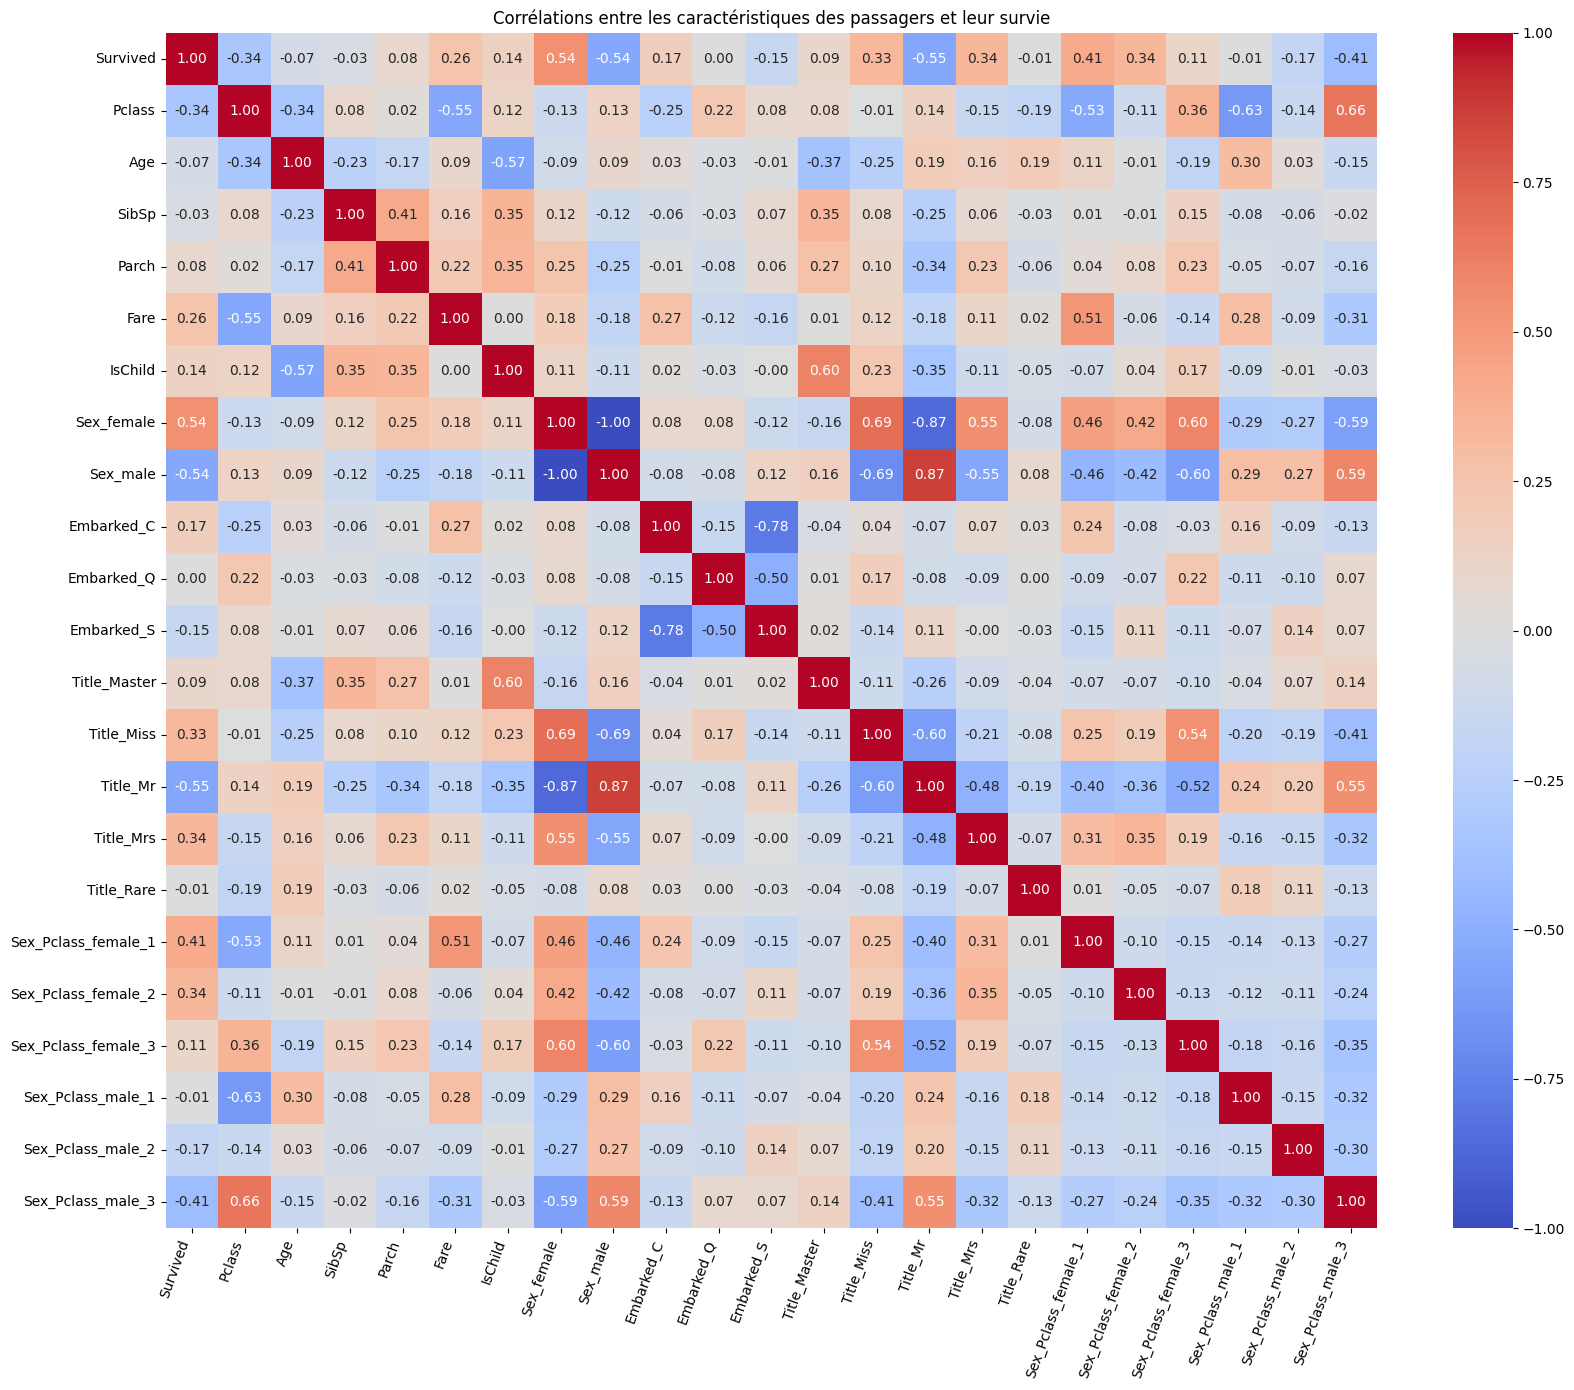

Corrélations avec Survived :


,Survived
Sex_female,0.541585
Sex_Pclass_female_1,0.408932
Title_Mrs,0.340870
Sex_Pclass_female_2,0.338848
Title_Miss,0.334953
Fare,0.255290
Embarked_C,0.169966
IsChild,0.137284
Sex_Pclass_female_3,0.106339
Title_Master,0.085998


In [ ]:
# Objectif : identifier les caractéristiques des passagers les plus associées à leur survie ou à leur décès, en incluant les variables catégorielles absentes de notre première matrice de corrélation.

# Création d'un DataFrame indépendant pour ne pas modifier df1
df_corr = df1[["Survived","Pclass", "Sex", "Age","SibSp", "Parch",  "Fare", "Embarked","Title", "IsChild", "Sex_Pclass"]].copy()

# Transformation des catégories en variables binaires (0 ou 1)
df_corr = pd.get_dummies(df_corr, columns=["Sex", "Embarked", "Title","Sex_Pclass"],dtype=int)

# Calcul de la matrice de corrélation
matrice_corr = df_corr.corr()

# Affichage de la matrice
plt.figure(figsize=(17, 14))

sns.heatmap(matrice_corr,annot=True,fmt=".2f",cmap="coolwarm",center=0)

plt.title("Corrélations entre les caractéristiques des passagers et leur survie")
plt.xticks(rotation=70, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Classement des caractéristiques selon leur corrélation avec la survie
print("Corrélations avec Survived :")
display(matrice_corr["Survived"].drop("Survived").sort_values(ascending=False))

### Analyse des caractéristiques associées à la survie

L'analyse de la matrice de corrélation met en évidence que **le sexe constitue la caractéristique la plus fortement associée à la survie des passagers du Titanic**. En effet, le fait d'être une femme présente une corrélation positive avec la survie (+0,542), tandis que le fait d'être un homme présente une corrélation négative équivalente (-0,542). Le titre « Mr » confirme cette tendance avec une corrélation négative de -0,548.

**Le statut social, représenté par la classe du passager, apparaît comme un second facteur important.** La variable Pclass présente une corrélation négative de -0,336 avec la survie, indiquant que les passagers des classes inférieures avaient globalement moins de chances de survivre.

La combinaison de ces deux caractéristiques renforce ce constat : être une femme de première classe présente une corrélation positive de +0,409 avec la survie, tandis qu'être un homme de troisième classe présente une corrélation négative de -0,407.

**En conclusion, le sexe apparaît comme le principal facteur associé à la survie, suivi du statut social.** Les autres caractéristiques étudiées présentent des corrélations individuelles plus faibles.
